# RF on baseline.csv (Predict DX at M06)

In [ ]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl(lessexc).csv')

In [2]:
data

,RID,AGE,PTEDUCAT,APOE4,CDRSB,ADAS11,ADAS13,MMSE,RAVLT_immediate,RAVLT_learning,...,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,PTGENDER_Female,PTGENDER_Male,DX,DX_m06
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,2321.0,6300.0,2289.0,741.500000,239.700000,22.830000,0,1,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,2175.0,923.0,1820.0,547.300000,337.000000,33.430000,0,1,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,1810.0,713.0,1999.0,1064.913718,284.614621,27.130365,1,0,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,2128.0,1867.0,1868.0,1064.913718,284.614621,27.130365,0,1,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,2131.0,556.0,2011.0,357.400000,329.900000,31.260000,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1087,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,2709.0,1739.0,2310.0,998.200000,472.000000,47.150000,1,0,0,0
1088,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,2247.0,2011.0,1397.0,1064.913718,284.614621,27.130365,1,0,1,1
1089,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,2922.0,183.0,2414.0,1087.000000,113.600000,9.020000,1,0,1,1
1090,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,2823.0,322.0,1663.0,1923.000000,228.600000,19.010000,0,1,1,1


In [ ]:
### Data Splitting

In [3]:
# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] ## independent features
y = data.iloc[:,-1] ## dependent features
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30, random_state=42)

In [ ]:
### Hyperparameter tuning

In [4]:
# Define the XGBoost classifier
clf = XGBClassifier()

# Define the hyperparameters to tune
params = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5],
    'gamma': [0, 0.1, 0.2],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

In [5]:
# Perform grid search to find the best hyperparameters
grid_search = GridSearchCV(clf, params, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 729 candidates, totalling 3645 fits


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     gamma=None, gpu_id=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None, max_bin=None,
                                     max_ca...
                                     missing=nan, monotone_constraints=None,
                                     n_estimators=100, n_jobs=None,
                                     num_parallel_tree=None, predictor=None,
                        

In [6]:
# Get the best hyperparameters and print them
best_params = grid_search.best_params_
print("Best hyperparameters:", best_params)

Best hyperparameters: {'colsample_bytree': 0.8, 'gamma': 0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}


In [ ]:
### Model training

In [7]:
# Train the XGBoost classifier with the best hyperparameters
clf = XGBClassifier(**best_params)
clf.fit(x_train, y_train)

XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=0.8,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, gamma=0, gpu_id=-1, grow_policy='depthwise',
              importance_type=None, interaction_constraints='',
              learning_rate=0.01, max_bin=256, max_cat_to_onehot=4,
              max_delta_step=0, max_depth=3, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=100,
              n_jobs=0, num_parallel_tree=1, objective='multi:softprob',
              predictor='auto', random_state=0, reg_alpha=0, ...)

In [ ]:
### Model Testing

In [8]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [9]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 0.9738219895287958
Testing accuracy: 0.9725609756097561
Confusion matrix:
 [[ 50   8   0]
 [  0 163   1]
 [  0   0 106]]


In [10]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      0.86      0.93        58
           1       0.95      0.99      0.97       164
           2       0.99      1.00      1.00       106

    accuracy                           0.97       328
   macro avg       0.98      0.95      0.96       328
weighted avg       0.97      0.97      0.97       328



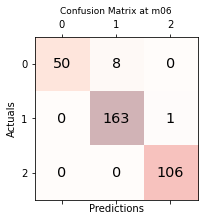

In [11]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Reds, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m06', fontsize=9)
plt.show()

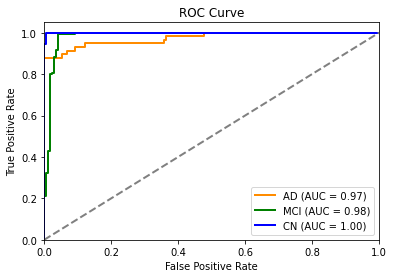

In [12]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

# on bl&m06.csv (Predict DX at M12)

In [13]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06(lessexc).csv')

In [14]:
data

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ABETA_UPENNBIOMK9_04_19_17_m06,TAU_UPENNBIOMK9_04_19_17_m06,PTAU_UPENNBIOMK9_04_19_17_m06,DX_m06,DX
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,3474.0,0.609,2491.0,6759.0,2380.0,741.500000,239.700000,22.830000,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,2710.0,0.551,2284.0,877.0,1858.0,547.300000,337.000000,33.430000,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,2736.0,0.607,1734.0,730.0,2001.0,1064.913718,284.614621,27.130365,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,2463.0,0.653,2093.0,1957.0,1758.0,1064.913718,284.614621,27.130365,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,3022.0,0.662,2013.0,637.0,1794.0,357.400000,329.900000,31.260000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1087,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,2550.0,0.793,2505.0,1909.0,2245.0,998.200000,472.000000,47.150000,0,0
1088,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,3281.0,0.743,2312.0,2122.0,1386.0,1064.913718,284.614621,27.130365,1,1
1089,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,3275.0,0.658,2984.0,147.0,2536.0,1087.000000,113.600000,9.020000,1,1
1090,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,3957.0,0.574,2894.0,322.0,1683.0,1923.000000,228.600000,19.010000,1,1


In [15]:
# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] ## independent features
y = data.iloc[:,-1] ## dependent features
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30, random_state=42)

In [16]:
# Define the XGBoost classifier
clf = XGBClassifier()

# Define the hyperparameters to tune
params = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5],
    'gamma': [0, 0.1, 0.2],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

In [17]:
# Perform grid search to find the best hyperparameters
grid_search = GridSearchCV(clf, params, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 729 candidates, totalling 3645 fits


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     gamma=None, gpu_id=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None, max_bin=None,
                                     max_ca...
                                     missing=nan, monotone_constraints=None,
                                     n_estimators=100, n_jobs=None,
                                     num_parallel_tree=None, predictor=None,
                        

In [18]:
# Get the best hyperparameters and print them
best_params = grid_search.best_params_
print("Best hyperparameters:", best_params)

Best hyperparameters: {'colsample_bytree': 1.0, 'gamma': 0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}


In [19]:
# Train the XGBoost classifier with the best hyperparameters
clf = XGBClassifier(**best_params)
clf.fit(x_train, y_train)

XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1.0,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, gamma=0, gpu_id=-1, grow_policy='depthwise',
              importance_type=None, interaction_constraints='',
              learning_rate=0.01, max_bin=256, max_cat_to_onehot=4,
              max_delta_step=0, max_depth=3, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=100,
              n_jobs=0, num_parallel_tree=1, objective='multi:softprob',
              predictor='auto', random_state=0, reg_alpha=0, ...)

In [20]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [21]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 0.9528795811518325
Testing accuracy: 0.9634146341463414
Confusion matrix:
 [[ 59  11   0]
 [  0 152   1]
 [  0   0 105]]


In [22]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      0.84      0.91        70
           1       0.93      0.99      0.96       153
           2       0.99      1.00      1.00       105

    accuracy                           0.96       328
   macro avg       0.97      0.95      0.96       328
weighted avg       0.97      0.96      0.96       328



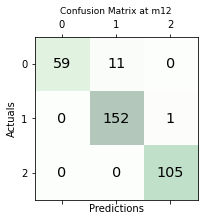

In [23]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Greens, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m12', fontsize=9)
plt.show()

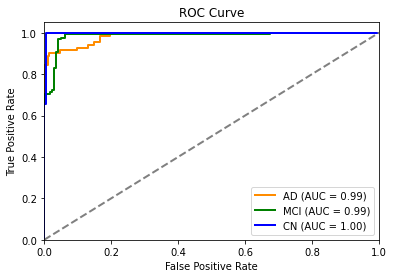

In [24]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

# on bl&m06&m12&m18(lessexc).csv (Predict DX at M24)

In [1]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06&m12&m18(lessexc).csv')

In [2]:
data

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ABETA_UPENNBIOMK9_04_19_17_m18,TAU_UPENNBIOMK9_04_19_17_m18,PTAU_UPENNBIOMK9_04_19_17_m18,DX_m18,DX_m24
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,3234.0,0.629,2117.0,6979.0,2362.0,601.400000,251.700000,24.180000,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,3112.0,0.570,2175.0,905.0,1894.0,472.800000,334.100000,34.040000,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,2745.0,0.644,1747.0,827.0,1954.0,1064.913718,284.614621,27.130365,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,2463.0,0.653,2093.0,1957.0,1758.0,1064.913718,284.614621,27.130365,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,2928.0,0.592,2087.0,681.0,1808.0,340.000000,287.700000,27.370000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1087,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,3186.0,0.728,2700.0,2115.0,2302.0,998.200000,472.000000,47.150000,0,0
1088,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,2883.0,0.689,2375.0,2487.0,1481.0,1064.913718,284.614621,27.130365,1,1
1089,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,3320.0,0.663,3072.0,129.0,2356.0,1087.000000,113.600000,9.020000,1,1
1090,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,3957.0,0.574,2894.0,322.0,1683.0,1923.000000,228.600000,19.010000,1,1


In [3]:
# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] ## independent features
y = data.iloc[:,-1] ## dependent features
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30, random_state=42)

In [4]:
# Define the XGBoost classifier
clf = XGBClassifier()

# Define the hyperparameters to tune
params = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5],
    'gamma': [0, 0.1, 0.2],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

In [5]:
# Perform grid search to find the best hyperparameters
grid_search = GridSearchCV(clf, params, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 729 candidates, totalling 3645 fits


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     gamma=None, gpu_id=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None, max_bin=None,
                                     max_ca...
                                     missing=nan, monotone_constraints=None,
                                     n_estimators=100, n_jobs=None,
                                     num_parallel_tree=None, predictor=None,
                        

In [6]:
# Get the best hyperparameters and print them
best_params = grid_search.best_params_
print("Best hyperparameters:", best_params)

Best hyperparameters: {'colsample_bytree': 0.9, 'gamma': 0, 'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}


In [7]:
# Train the XGBoost classifier with the best hyperparameters
clf = XGBClassifier(**best_params)
clf.fit(x_train, y_train)

XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=0.9,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, gamma=0, gpu_id=-1, grow_policy='depthwise',
              importance_type=None, interaction_constraints='',
              learning_rate=0.01, max_bin=256, max_cat_to_onehot=4,
              max_delta_step=0, max_depth=5, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=100,
              n_jobs=0, num_parallel_tree=1, objective='multi:softprob',
              predictor='auto', random_state=0, reg_alpha=0, ...)

In [8]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [9]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 0.975130890052356
Testing accuracy: 0.9146341463414634
Confusion matrix:
 [[ 85  22   0]
 [  2 114   4]
 [  0   0 101]]


In [10]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.98      0.79      0.88       107
           1       0.84      0.95      0.89       120
           2       0.96      1.00      0.98       101

    accuracy                           0.91       328
   macro avg       0.93      0.91      0.92       328
weighted avg       0.92      0.91      0.91       328



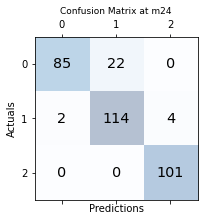

In [11]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Blues, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m24', fontsize=9)
plt.show()

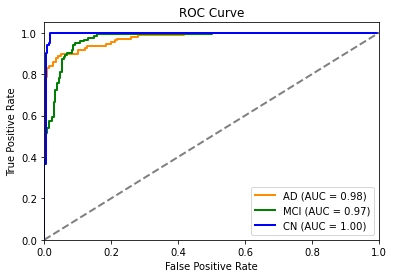

In [12]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute predicted probabilities for each class
y_prob = clf.predict_proba(x_test)

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()


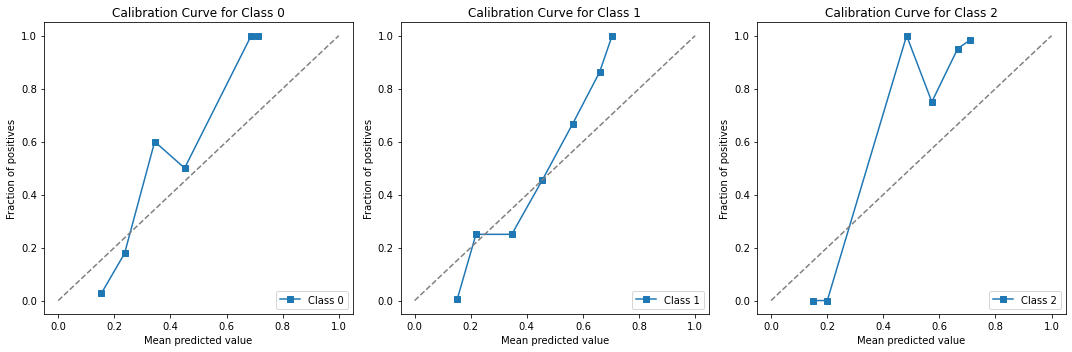

In [37]:
from sklearn.calibration import calibration_curve

y_prob = clf.predict_proba(x_test)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for i in range(3):
    ax = axs[i]
    y_true_i = (y_test == i).astype(int)
    probs_i = y_prob[:, i]
    fraction_of_positives, mean_predicted_value = calibration_curve(y_true_i, probs_i, n_bins=10)
    ax.plot(mean_predicted_value, fraction_of_positives, 's-', label='Class %d' % i)
    ax.plot([0, 1], [0, 1], '--', color='gray')
    ax.set_xlabel('Mean predicted value')
    ax.set_ylabel('Fraction of positives')
    ax.set_ylim([-0.05, 1.05])
    ax.legend(loc='lower right')
    ax.set_title('Calibration Curve for Class %d' % i)
    
plt.tight_layout()
plt.show()

# on bl&m06&m12(less).csv (Predict DX at M18)

In [13]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06&m12(lessexc).csv')

In [14]:
data

,RID,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,...,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,DX,DX_m18
0,3,81.3,18,1,4.5,22.00,31.00,20,22.0,1.0,...,3234.0,0.629,2117.0,6979.0,2362.0,601.400000,251.700000,24.180000,0,0
1,5,73.7,16,0,0.0,8.67,14.67,29,37.0,4.0,...,3112.0,0.570,2175.0,905.0,1894.0,472.800000,334.100000,34.040000,2,2
2,6,80.4,13,0,0.5,18.67,25.67,25,30.0,1.0,...,2791.0,0.673,1713.0,737.0,2124.0,1064.913718,284.614621,27.130365,1,1
3,7,75.4,10,1,6.0,27.33,40.33,20,17.0,2.0,...,2463.0,0.653,2093.0,1957.0,1758.0,1064.913718,284.614621,27.130365,0,0
4,10,73.9,12,1,5.0,12.33,24.33,24,20.0,2.0,...,2928.0,0.592,2087.0,681.0,1808.0,340.000000,287.700000,27.370000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1087,4962,80.1,18,2,3.5,15.00,24.00,22,18.0,0.0,...,3186.0,0.728,2700.0,2115.0,2302.0,998.200000,472.000000,47.150000,0,0
1088,4985,78.7,13,1,1.0,11.00,19.00,26,29.0,2.0,...,2883.0,0.689,2375.0,2487.0,1481.0,1064.913718,284.614621,27.130365,1,1
1089,4989,60.1,19,0,1.0,6.00,7.00,29,51.0,6.0,...,3320.0,0.663,3072.0,129.0,2356.0,1087.000000,113.600000,9.020000,1,1
1090,5004,64.6,20,0,1.5,6.00,12.00,29,37.0,2.0,...,3957.0,0.574,2894.0,322.0,1683.0,1923.000000,228.600000,19.010000,1,1


In [15]:
# Create the training and testing feature and label sets
x = data.iloc[:,1:-1] ## independent features
y = data.iloc[:,-1] ## dependent features
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.30, random_state=42)

In [16]:
# Define the XGBoost classifier
clf = XGBClassifier()

# Define the hyperparameters to tune
params = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5],
    'gamma': [0, 0.1, 0.2],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

In [17]:
# Perform grid search to find the best hyperparameters
grid_search = GridSearchCV(clf, params, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 729 candidates, totalling 3645 fits


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     gamma=None, gpu_id=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None, max_bin=None,
                                     max_ca...
                                     missing=nan, monotone_constraints=None,
                                     n_estimators=100, n_jobs=None,
                                     num_parallel_tree=None, predictor=None,
                        

In [18]:
# Get the best hyperparameters and print them
best_params = grid_search.best_params_
print("Best hyperparameters:", best_params)

Best hyperparameters: {'colsample_bytree': 0.9, 'gamma': 0.1, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}


In [19]:
# Train the XGBoost classifier with the best hyperparameters
clf = XGBClassifier(**best_params)
clf.fit(x_train, y_train)

XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=0.9,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, gamma=0.1, gpu_id=-1, grow_policy='depthwise',
              importance_type=None, interaction_constraints='',
              learning_rate=0.1, max_bin=256, max_cat_to_onehot=4,
              max_delta_step=0, max_depth=3, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=200,
              n_jobs=0, num_parallel_tree=1, objective='multi:softprob',
              predictor='auto', random_state=0, reg_alpha=0, ...)

In [20]:
# Make predictions on the training and testing sets
y_train_pred = clf.predict(x_train)
y_test_pred = clf.predict(x_test)
y_prob=clf.predict_proba(x_test)
# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

In [21]:
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

Training accuracy: 1.0
Testing accuracy: 0.9634146341463414
Confusion matrix:
 [[ 73  10   0]
 [  2 138   0]
 [  0   0 105]]


In [22]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.97      0.88      0.92        83
           1       0.93      0.99      0.96       140
           2       1.00      1.00      1.00       105

    accuracy                           0.96       328
   macro avg       0.97      0.96      0.96       328
weighted avg       0.96      0.96      0.96       328



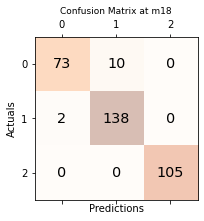

In [23]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Oranges, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at m18', fontsize=9)
plt.show()

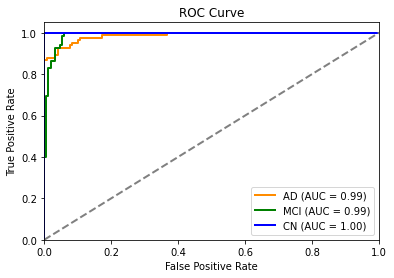

In [24]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()